# Pipeline

**To test a forecaster fairly, you fit a fresh copy on every test series, check and score every forecast, and keep what came out. `Pipeline` does all of it in one call.**

This chapter builds `timegym.pipeline` and `timegym.evaluation`. Wrap any model in a `Pipeline`: `test` returns a report of verdicts and errors over many generated series, `predict` forecasts one history of your own, `scorecard` grades the model from 0 to 100 on a fixed grid, and `run` keeps every series and forecast for plots.

Below we test a six-line model of our own, see what goes wrong when one model object is reused across cases, print a scorecard, and keep a run of a Ridge regression to plot its forecasts and errors. Then we change one setting at a time on the same draws.

**Development notebook.** The collapsed cells are the source of `timegym/evaluation.py` and `timegym/pipeline.py`; expand them to edit, then restart the kernel and Run All ([build workflow](README.md#develop-the-package-here)).

In [1]:
#| default_exp evaluation

In [2]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

%matplotlib inline
plt.rcParams.update({'figure.figsize': (12, 4), 'figure.dpi': 110, 'font.size': 11,
                     'figure.facecolor': 'white', 'axes.facecolor': 'white',
                     'axes.spines.top': False, 'axes.spines.right': False,
                     'axes.grid': False, 'legend.frameon': False, 'axes.titlelocation': 'left'})
pd.set_option('display.max_colwidth', None)

## What a run keeps (`timegym.evaluation`)

Two containers for evaluated cases. The plots they draw live in [Plotting](11_plotting.ipynb), imported only when a plot is drawn.

### Imports

In [3]:
#| export evaluation
from __future__ import annotations

from dataclasses import dataclass, field
from typing import Any

from timegym.contracts import Forecast
from timegym.reporting import CaseResult, TestReport
from timegym.scenarios import Case

### One case, its forecast and its verdicts (`EvaluatedCase`)

The generated case, exactly what the model returned, and the checks and scores. `forecast` is `None` when the model crashed. The scenario and seed positions keep two identical scenarios, or two equal seeds, apart.

In [4]:
#| export evaluation
@dataclass
class EvaluatedCase:
    """One generated case, its actual model output, and its diagnostic result.

    ``forecast`` is absent when model execution failed. Positional scenario
    and seed identities keep repeated scenario kinds and seeds distinct.
    """

    case: Case
    forecast: Forecast | None
    result: CaseResult
    scenario_index: int
    seed_index: int

### A whole run, kept in memory (`ForecastRun`)

Every evaluated case, plus the run's metadata. `report` gives the usual `TestReport`, which holds verdicts and scores but no arrays. `plot_forecasts` and `plot_errors` draw from the kept forecasts without fitting again. `titles` can name each scenario in plain words for the plots; the scorecard sets them.

In [5]:
#| export evaluation
@dataclass
class ForecastRun:
    """Retain the evidence needed to inspect a run without fitting again.

    Arrays remain in memory; ``report`` uses the JSON report schema and does
    not embed contexts, observations, or forecast arrays. ``titles``
    optionally names each scenario position in plain words for the plots (a
    scorecard sets them to the pattern and noise level); they are not saved
    in the report. Plotting requires Matplotlib, imported only when a plot is
    drawn.
    """

    cases: list[EvaluatedCase]
    metadata: dict[str, Any] = field(default_factory=dict)
    titles: list[str] = field(default_factory=list)

    @property
    def report(self) -> TestReport:
        """Return the usual structured report for these evaluated cases."""
        return TestReport(cases=[entry.result for entry in self.cases], metadata=self.metadata)

    def plot_forecasts(self, *, show_quantiles=False, figsize=None, history=None):
        """Plot scenario/target rows by seed columns, using retained outputs.

        Gray dots are observations, the black line is the answer key and blue
        crosses are the forecast, with each case's score above its panel.
        ``history`` is how many past steps to show (four times the horizon by
        default, ``"all"`` for everything). Optional bands use explicit
        marginal quantiles; samples never imply a point forecast.
        """
        from timegym.plotting import plot_forecasts

        return plot_forecasts(self, show_quantiles=show_quantiles, figsize=figsize, history=history)

    def plot_errors(self, metric="mean_reference_mse", *, bins=None, missing="raise", figsize=None):
        """Plot per-scenario score distributions without rerunning a model.

        Missing/nonfinite scores raise by default. Set ``missing='annotate'``
        to show their counts and diagnostic reasons explicitly in each panel.
        Each score is one whole-case metric from the existing report.
        """
        from timegym.plotting import plot_errors

        return plot_errors(self, metric=metric, bins=bins, missing=missing, figsize=figsize)

## Fit, forecast and score (`timegym.pipeline`)

### Imports

In [6]:
# Keep the live source types before the next module's package imports.
_notebook_run_types = (EvaluatedCase, ForecastRun)

In [7]:
#| export pipeline
from __future__ import annotations
from timegym._internal import positive_int, nonnegative_int

import dataclasses
import inspect
import secrets
import numpy as np
import pandas as pd
from timegym.contracts import Forecast, ForecastTask
from timegym.models import REDUCTIONS, NaiveForecaster, SklearnForecaster, fresh_model, is_sklearn_regressor
from timegym.scenarios import Scenario, MANIFEST_SCHEMA_VERSION
from timegym.data.synthetic import default_scenarios
from timegym.diagnostics import evaluate_forecast, exception_evidence
from timegym.reporting import CaseResult, DiagnosticResult, TestReport
from timegym.evaluation import EvaluatedCase, ForecastRun
from timegym.provenance import pipeline_config, pipeline_from_config, diagnostic_settings, runtime_provenance

### The pipeline (`Pipeline`)

A model is anything with `fit(history)` and `predict(dates)`. Pass an instance (copied before every case), a class (constructed for every case), or `model_factory=`, a function that returns a new unfitted model. A scikit-learn regressor passed as the model, or steps added with `add()`, become a forecaster through `window_length` and `reduction`; other models ignore both. An optional `target_transform` is refitted on each history before the model sees it and undone on the forecast.

Whatever the model's `predict` returns (a list, an array, a Series, a DataFrame or a `Forecast`) becomes a `Forecast` before the output checks. A list or array is read as the requested steps in order, one column per series; a Series or DataFrame keeps its own dates and names, so wrong ones still fail their checks.

`predict` forecasts one history, `run` evaluates every scenario and seed and keeps everything, `test` returns only the report, `scorecard` grades the model on the standard grid, and `plot_tests` and `plot_errors` run and plot in one call. Draw `i` uses seed `seed + i` in every scenario, so every model tested with the same seeds sees the same series.

In [8]:
#| export pipeline
def _as_context(context):
    """The past as a DataFrame: one row per time step, one column per series.

    A list or NumPy array has no time labels, so its rows are labelled 0, 1,
    2, ... and its columns ``y`` (one series) or 0, 1, ... (several series).
    """
    if isinstance(context, pd.DataFrame):
        return context
    if isinstance(context, pd.Series):
        return context.to_frame(name=context.name if context.name is not None else "y")
    if isinstance(context, (list, tuple, np.ndarray)):
        values = np.asarray(context)
        if values.ndim == 1:
            return pd.DataFrame({"y": values})
        if values.ndim == 2:
            return pd.DataFrame(values)
    raise TypeError(
        "context must be a pandas DataFrame or Series, a list, or a one- or two-dimensional "
        "NumPy array"
    )


def _one_value_per_step(values, names):
    """Read one value per step as one row per step when there is a single series."""
    try:
        array = np.asarray(values)
    except (TypeError, ValueError):
        return values  # ragged or non-numeric: the output checks report it
    if array.ndim == 1 and names is not None and len(names) == 1:
        return array[:, None]
    return array


def _as_forecast(output, task):
    """Turn whatever the model's ``predict`` returned into a Forecast to check.

    - A list or NumPy array holds one value per step for one series, or one
      row per step and one column per series. Its rows are the requested
      future steps in order and its columns the context's series in order.
    - A pandas DataFrame or Series keeps its own index and column names, so
      wrong dates or a wrong series order still fail their checks. An unnamed
      Series stands for the task's single series.
    - A Forecast is used as given. Without ``target_names`` its series are the
      task's, and a one-dimensional ``point`` for one series is one value per step.
    """
    if isinstance(output, Forecast):
        names = task.target_names if output.target_names is None else output.target_names
        point = output.point
        if point is not None:
            point = _one_value_per_step(point, names)
        if names is output.target_names and point is output.point:
            return output
        return dataclasses.replace(output, point=point, target_names=names)
    if isinstance(output, pd.Series):
        if output.name is None and len(task.target_names) == 1:
            names = task.target_names
        else:
            names = (output.name if output.name is not None else "y",)
        return Forecast(output.index, point=output.to_numpy()[:, None], target_names=names)
    if isinstance(output, pd.DataFrame):
        return Forecast(output.index, point=output.to_numpy(), target_names=tuple(output.columns))
    if isinstance(output, (list, tuple, np.ndarray)):
        return Forecast(
            task.future_index.copy(),
            point=_one_value_per_step(output, task.target_names),
            target_names=task.target_names,
        )
    raise TypeError(
        "model.predict(future_index) must return one value per future step: a list or NumPy "
        "array, a pandas Series or DataFrame indexed by future_index, or a timegym.Forecast; "
        f"got {type(output).__name__}"
    )


def _instance_seeds(seeds, seed, instances, default_instances):
    """Return the case seeds and the seeding record for run metadata.

    With an explicit ``seeds`` list nothing else is derived. Otherwise
    instance ``i`` uses ``seed + i``; ``seed=None`` draws a fresh base seed,
    which is recorded so the run can be repeated.
    """
    if seeds is not None:
        if seed != 0 or instances is not None:
            raise ValueError("Pass either seeds=[...] or seed/instances, not both")
        return [nonnegative_int(value, "seed") for value in seeds], None
    count = positive_int(default_instances if instances is None else instances, "instances")
    base = secrets.randbelow(2**31) if seed is None else nonnegative_int(seed, "seed")
    return [base + i for i in range(count)], {"seed": base, "instances": count}


class Pipeline:
    """Evaluate fresh model instances on independent, seeded scenarios.

    Native models implement fit(context) and predict(future_index). The
    context is the past as a DataFrame, one row per time step and one column
    per series (``y`` for one series). ``future_index`` holds the labels of the
    steps to forecast, continuing the context's index. ``predict`` returns one
    value per step: a list or NumPy array (one column per series when there
    are several), a Series or DataFrame indexed by ``future_index``, or a
    Forecast, which can also carry quantiles and samples. Supply a model
    instance (copied before every case), a class, or a model_factory
    producing a fresh unfitted instance.
    sklearn regressors/transformers can be added with add(); ``reduction``
    selects one of REDUCTIONS for them and, like ``window_length``, does not
    change native models. An optional ``target_transform`` is refitted on
    each context before the model and inverted on the forecast it returns.
    """

    def __init__(self, model=None, window_length=12, reduction="recursive", *, model_factory=None,
                 target_transform=None):
        if reduction not in REDUCTIONS:
            raise ValueError(f"Unknown reduction {reduction!r}; choose from {REDUCTIONS}")
        protocol = ("clone_unfitted", "fit_transform", "inverse_transform")
        if target_transform is not None and (inspect.isclass(target_transform) or not all(
                callable(getattr(target_transform, name, None)) for name in protocol)):
            raise TypeError("target_transform must be an instance implementing clone_unfitted(), "
                            "fit_transform(context) and inverse_transform(forecast)")
        self.model = model
        if model is not None and model_factory is not None:
            raise ValueError("Specify model or model_factory, not both")
        if model_factory is not None and not callable(model_factory):
            raise TypeError("model_factory must be a callable producing a fresh unfitted model")
        self.model_factory = model_factory
        window_length = positive_int(window_length, 'window_length')
        self.window_length = int(window_length)
        self.reduction = reduction
        self.target_transform = target_transform
        self.steps = []

    def add(self, estimator, **parameters):
        """Add an sklearn transformer or final regressor; returns self."""
        if self.model is not None or self.model_factory is not None:
            raise ValueError("Use a native model or sklearn steps, not both")
        if inspect.isclass(estimator):
            estimator = estimator(**parameters)
        elif parameters:
            estimator = fresh_model(estimator).set_params(**parameters)
        self.steps.append(estimator)
        return self

    def _model(self, horizon):
        if self.steps:
            return SklearnForecaster(self.steps, self.window_length, reduction=self.reduction, horizon=horizon)
        if self.model is None and self.model_factory is None:
            return NaiveForecaster()
        newly_constructed = self.model_factory is not None or inspect.isclass(self.model)
        candidate = self.model_factory() if self.model_factory is not None else (self.model() if inspect.isclass(self.model) else self.model)
        if callable(getattr(candidate, "clone_unfitted", None)):
            return candidate if newly_constructed else fresh_model(candidate)
        if is_sklearn_regressor(candidate):
            return SklearnForecaster([candidate], self.window_length, reduction=self.reduction, horizon=horizon)
        return candidate if newly_constructed else fresh_model(candidate)

    def _model_name(self) -> str:
        if self.steps:
            return "SklearnForecaster"
        if self.model_factory is not None:
            return getattr(self.model_factory, "__qualname__", "model_factory")
        if inspect.isclass(self.model):
            return self.model.__name__
        if self.model is not None:
            return type(self.model).__name__
        return "NaiveForecaster"

    def to_config(self):
        """Return JSON-safe configuration and whether safe automatic replay is supported."""
        return pipeline_config(self)

    @classmethod
    def from_config(cls, config):
        """Rebuild allowlisted built-in models and target transforms without dynamic imports."""
        return cls(**pipeline_from_config(config))

    def predict(self, context, future_index):
        """Fit on context and predict the supplied index, without future targets.

        ``context`` is the past: a DataFrame with one column per series, a
        Series, or a list or NumPy array, whose rows are labelled 0, 1, 2, ...
        ``future_index`` is any sequence of the labels to forecast; after a
        list of 120 values the next 12 steps are ``range(120, 132)``.

        A target transform is refitted on this context alone and the model sees
        only the transformed context. A forecast that meets its contract is
        inverted to the original scale; one that violates it is returned
        unchanged, so evaluation reports the model's fault, not the inversion's.
        """
        context = _as_context(context)
        if not isinstance(future_index, pd.Index):
            future_index = pd.Index(future_index)
        # Share the public task contract, including unique target names.
        task = ForecastTask(context=context, future_index=future_index)
        transform = None
        if self.target_transform is not None:
            transform = self.target_transform.clone_unfitted()
            if transform is self.target_transform:
                raise ValueError("clone_unfitted() must return a new target transform instance")
            task = ForecastTask(context=transform.fit_transform(context.copy(deep=True)), future_index=future_index)
        model = self._model(len(future_index))
        model.fit(task.context.copy(deep=True))
        forecast = _as_forecast(model.predict(future_index.copy()), task)
        if transform is not None and not forecast.validate(task):
            forecast = transform.inverse_transform(forecast)
        return forecast

    def run(self, scenarios=None, seeds=None, *, seed=0, instances=None, check_dependence=False,
            n_calibration=99, alpha=0.05, dependence_seed_offset=100_000):
        """Evaluate once per case and retain the data, forecast, and diagnostics.

        Each scenario is drawn ``instances`` times (default 3). Instance ``i``
        uses seed ``seed + i`` in every scenario, so scenarios are compared on
        the same random draws. ``seed=None`` picks a fresh base seed and
        records it in ``run.metadata["seed"]``. An explicit ``seeds`` list
        replaces both. ``run.report`` is the usual serializable
        ``TestReport``; ``run.plot_forecasts()`` and ``run.plot_errors()``
        inspect these exact outputs without additional fitting.
        """
        if self.steps:
            SklearnForecaster(self.steps, self.window_length)
        settings = diagnostic_settings(check_dependence=check_dependence, n_calibration=n_calibration,
                                       alpha=alpha, dependence_seed_offset=dependence_seed_offset)
        seeds, seeding = _instance_seeds(seeds, seed, instances, 3)
        if scenarios is None:
            scenarios = default_scenarios()
        scenarios = list(scenarios)
        if not scenarios or not seeds:
            raise ValueError("Provide at least one scenario and one seed")
        results = []
        for scenario_index, scenario in enumerate(scenarios):
            for seed_index, case_seed in enumerate(seeds):
                case = scenario.generate(seed=case_seed)
                forecast = None
                try:
                    forecast = self.predict(case.task.context, case.task.future_index)
                    result = evaluate_forecast(case, forecast, check_dependence=check_dependence,
                                               dependence_seed=int(case_seed) + dependence_seed_offset,
                                               n_calibration=n_calibration, alpha=alpha)
                except Exception as exc:
                    result = CaseResult(scenario=scenario.kind, seed=int(case_seed), diagnostics=[
                        DiagnosticResult(name="model_execution", status="ERROR", category="execution",
                                         message=f"{type(exc).__name__}: {exc}",
                                         evidence=exception_evidence(exc))],
                        metrics={}, manifest=case.manifest)
                results.append(EvaluatedCase(case=case, forecast=forecast, result=result,
                                             scenario_index=scenario_index, seed_index=seed_index))
        config = self.to_config()
        return ForecastRun(cases=results, metadata={**runtime_provenance(), "numpy": np.__version__,
                          "pandas": pd.__version__, "model": self._model_name(),
                          "window_length": self.window_length, "reduction": self.reduction,
                          "target_transform": config["target_transform"],
                          "pipeline_config": config, "diagnostic_settings": settings,
                          **(seeding or {})})

    def test(self, scenarios=None, seeds=None, *, seed=0, instances=None, check_dependence=False,
             n_calibration=99, alpha=0.05, dependence_seed_offset=100_000):
        """Evaluate each scenario on each instance and return a TestReport.

        Seeds work as in ``run``: instance ``i`` uses ``seed + i``.
        """
        return self.run(scenarios, seeds=seeds, seed=seed, instances=instances,
                        check_dependence=check_dependence, n_calibration=n_calibration, alpha=alpha,
                        dependence_seed_offset=dependence_seed_offset).report

    def scorecard(self, patterns=None, *, noise_levels=2, instances=10, seed=0, context_length=120,
                  horizon=24, title=None):
        """Score the model on a grid of patterns and noise levels; returns a Scorecard.

        Rows are patterns from ``timegym.PATTERNS`` (all ten by default) and
        columns are noise levels from low to high. Each cell is drawn
        ``instances`` times with seeds ``seed + i``. Display the result in a
        notebook, ``print`` it as Markdown, or ``save`` it as an image. See
        ``timegym.scorecard.scorecard`` for the score and its mistakes.
        """
        from timegym.scorecard import scorecard

        return scorecard(self, patterns, noise_levels=noise_levels, instances=instances, seed=seed,
                         context_length=context_length, horizon=horizon, title=title)

    def plot_tests(self, scenarios=None, seeds=None, *, seed=0, instances=None, show_quantiles=False,
                   figsize=None, history=None, **diagnostic_settings):
        """Fit a display suite and return its forecast matrix Figure.

        Display defaults use 240 context observations and 80 forecast steps;
        ``test`` and ``run`` keep their defaults of 120 context rows and 12
        steps. To make several figures from the same fits, use ``run`` and its
        plot methods.
        """
        if scenarios is None:
            scenarios = default_scenarios(context_length=240, horizon=80)
        return self.run(scenarios, seeds=seeds, seed=seed, instances=instances,
                        **diagnostic_settings).plot_forecasts(show_quantiles=show_quantiles, figsize=figsize,
                                                              history=history)

    def plot_errors(self, scenarios=None, seeds=None, *, seed=0, instances=None, metric="mean_reference_mse",
                    bins=None, missing="raise", figsize=None, **diagnostic_settings):
        """Fit once per requested case and plot the retained score distribution.

        This convenience call draws 20 instances by default. Use an existing
        run's ``plot_errors`` method to inspect previously evaluated forecasts.
        """
        if seeds is None and instances is None:
            instances = 20
        return self.run(scenarios, seeds=seeds, seed=seed, instances=instances,
                        **diagnostic_settings).plot_errors(metric=metric, bins=bins, missing=missing,
                                                           figsize=figsize)

### Replay one case from a saved report (`replay_case`)

Rebuilds the pipeline from the report, regenerates the case from its recipe, reruns every check, and records what matched and whether the environment is the same. [Reports and replay](10_reports_and_replay.ipynb) puts it to use.

In [9]:
#| export pipeline
def _without_tracebacks(value):
    if isinstance(value, dict):
        return {key: _without_tracebacks(item) for key, item in value.items() if key != "traceback"}
    if isinstance(value, list):
        return [_without_tracebacks(item) for item in value]
    return value


def _tracebacks(value, path=()):
    found = {}
    if isinstance(value, dict):
        for key, item in value.items():
            if key == "traceback":
                found[path + (key,)] = item
            else:
                found.update(_tracebacks(item, path + (key,)))
    elif isinstance(value, list):
        for index, item in enumerate(value):
            found.update(_tracebacks(item, path + (index,)))
    return found


def replay_case(report: TestReport, case_index=0):
    """Replay one report case and compare regenerated metrics and diagnostics.

    The return value is a new TestReport. ``metadata['replay']`` records exact
    result equality excluding tracebacks, plus traceback and environment agreement.
    Replaying in a different environment is allowed and reported.
    """
    if not isinstance(report, TestReport):
        raise TypeError("replay_case requires a TestReport; load saved data with TestReport.from_dict")
    payload = report.to_dict()
    case_index = nonnegative_int(case_index, "case_index")
    if case_index >= len(report.cases):
        raise ValueError("case_index is outside the saved report")
    original = payload["cases"][case_index]
    saved_metadata = payload["metadata"]
    pipeline = Pipeline.from_config(saved_metadata.get("pipeline_config"))
    settings = saved_metadata.get("diagnostic_settings")
    setting_keys = {"check_dependence", "n_calibration", "alpha", "dependence_seed_offset"}
    if not isinstance(settings, dict) or set(settings) != setting_keys:
        raise ValueError("Report diagnostic settings are absent or unsupported")
    settings = diagnostic_settings(**settings)
    manifest = original["manifest"]
    if type(manifest.get("schema_version")) is not int or manifest["schema_version"] != MANIFEST_SCHEMA_VERSION:
        raise ValueError("Unsupported scenario manifest schema")
    constructor_keys = ("kind", "context_length", "horizon", "parameters", "n_targets", "seed")
    if any(key not in manifest for key in constructor_keys):
        raise ValueError("Scenario manifest lacks required reconstruction fields")
    if original.get("seed") != manifest["seed"] or original.get("scenario") != manifest["kind"]:
        raise ValueError("Case identity and scenario manifest disagree")
    scenario = Scenario(**{key: manifest[key] for key in constructor_keys})
    regenerated = pipeline.test([scenario], seeds=[manifest["seed"]], **settings)
    actual = regenerated.cases[0].to_dict()
    regenerated.metadata["replay"] = {
        "case_index": case_index,
        "metrics_match": actual["metrics"] == original.get("metrics"),
        "diagnostics_match": _without_tracebacks(actual["diagnostics"]) == _without_tracebacks(original["diagnostics"]),
        "traceback_match": _tracebacks(actual["diagnostics"]) == _tracebacks(original["diagnostics"]),
        "manifest_match": actual["manifest"] == manifest,
        "source_matches": regenerated.metadata["source"] == saved_metadata.get("source"),
        "dependencies_match": regenerated.metadata["dependencies"] == saved_metadata.get("dependencies"),
        "python_matches": regenerated.metadata["python"] == saved_metadata.get("python"),
    }
    comparison = regenerated.metadata["replay"]
    comparison["reproduced"] = all(comparison[key] for key in ("metrics_match", "diagnostics_match", "manifest_match"))
    comparison["same_environment"] = all(comparison[key] for key in ("source_matches", "dependencies_match", "python_matches"))
    return regenerated

In [10]:
# The pipeline imports above replaced this chapter's EvaluatedCase and ForecastRun with
# the installed copies. Pipeline.run looks them up when called, so rebind the live ones.
EvaluatedCase, ForecastRun = _notebook_run_types
assert EvaluatedCase.__module__ == ForecastRun.__module__ == __name__
assert Pipeline.__module__ == __name__

## Test your own model

A model needs two methods. `fit(context)` gets the history: a DataFrame with one row per time step and one column per series. `predict(future_index)` gets the dates to forecast, which continue where the history ends, and returns one value per date. This one forecasts that every future value equals the last one seen.

`test` then does the work for every scenario and seed: it generates the series, fits a fresh copy of the model on the history, asks for the dates to forecast, runs the output checks, and scores the forecast against the **answer key** (the best forecast a forecaster that knows the true recipe could make from the same history) and against what actually happened. We try it on a random walk and on noise around a straight line, three draws each:

In [11]:
from timegym import Forecast, Scenario


class LastValueForecaster:
    def fit(self, context):
        self.last = context.iloc[-1]   # the last row: one value per series
        return self

    def predict(self, future_index):
        return Forecast(future_index, [self.last] * len(future_index))


KINDS = {'random_walk': 'Random walk', 'trend': 'Noise around a straight line',
         'seasonal': 'Noise around a repeating cycle'}
report = Pipeline(LastValueForecaster()).test([Scenario('random_walk', 120, 12), Scenario('trend', 120, 12)],
                                              instances=3)
report.assert_passed()  # raises if any forecast broke an output check
pd.DataFrame([{'series': KINDS[case.scenario], 'seed': case.seed,
               'output checks': case.diagnostics[0].status,
               'error against the answer key': case.metrics['mean_reference_mse'],
               'error against what happened': case.metrics['mse']} for case in report.cases]).round(2)

,series,seed,output checks,error against the answer key,error against what happened
0,Random walk,0,PASS,0.00,5.67
1,Random walk,1,PASS,0.00,3.00
2,Random walk,2,PASS,0.00,3.09
3,Noise around a straight line,0,PASS,0.38,1.25
4,Noise around a straight line,1,PASS,0.12,1.95
5,Noise around a straight line,2,PASS,0.48,0.67


Every case passed the output checks, so `assert_passed()` returned quietly. On the random walk the error against the answer key is 0.00: when shocks never fade, the last value is the answer key. Its error against what happened is still between 3.00 and 5.67, noise that no forecaster could predict, which is why TimeGym scores against the answer key. On the straight line the last value stays flat while the line climbs, and the error against the answer key (0.12 to 0.48) measures that mistake.

## A fresh model for every case

`test` never fits the object you pass in. Before every case it makes a fresh copy: TimeGym's own models rebuild themselves from their settings, scikit-learn estimators are cloned, and anything else, like `LastValueForecaster`, is deep-copied. That matters for any model that keeps something between fits. This one forecasts the average of every value it has ever been fitted on. We test it on noise around three levels, 0, 10 and 20, once through the pipeline and once by hand with one object reused:

In [12]:
class RememberingMean:
    """Forecasts the average of every value it has ever been fitted on."""

    def __init__(self):
        self.seen = []

    def fit(self, context):
        self.seen.extend(context['y'])
        return self

    def predict(self, future_index):
        return [float(np.mean(self.seen))] * len(future_index)


levels = [Scenario('white_noise', 120, 12, {'mean': level}) for level in (0., 10., 20.)]
model = RememberingMean()
fresh = Pipeline(model).test(levels, seeds=[0])
reused = RememberingMean()
rows = []
for scenario, result in zip(levels, fresh.cases):
    case = scenario.generate(seed=0)
    forecast = np.asarray(reused.fit(case.task.context).predict(case.task.future_index))
    rows.append({'level of the series': scenario.parameters['mean'],
                 'reused object forecasts': forecast[0],
                 'error, fresh copy each case (Pipeline)': result.metrics['mean_reference_mse'],
                 'error, one object reused': float(np.mean((forecast - case.reference.mean[:, 0]) ** 2))})
assert model.seen == []  # the object you passed in was never fitted
pd.DataFrame(rows).set_index('level of the series').round(2)

,reused object forecasts,"error, fresh copy each case (Pipeline)","error, one object reused"
level of the series,,,
0.0,0.08,0.01,0.01
10.0,5.08,0.01,24.19
20.0,10.08,0.01,98.38


With a fresh copy, each forecast is the average of its own history, and the error against the answer key is 0.01 at every level; the object we passed in was never fitted at all. The reused object averages everything it has seen: it forecasts 5.08 for the series at 10 and 10.08 for the series at 20, with errors of 24.19 and 98.38, and its results would change if the cases came in another order. Real models keep things between fits too: a warm-started network, an online learner, a scaler fitted once. A fresh copy for every case makes each result depend only on its own history, so a case can be compared across models and replayed on its own.

## One forecast from your own history

`Pipeline.predict(history, dates)` runs one case of that loop on data you supply: it fits a fresh copy on the history and returns a `Forecast`. The history can be a DataFrame, a Series, a list or an array. A list has no dates, so its rows are labeled 0, 1, 2 and the next three steps are 3, 4 and 5. The model's own `predict` may return a plain list too, and the same model handles several series:

In [13]:
class LastValueList(LastValueForecaster):
    def predict(self, future_index):
        return [float(self.last.iloc[0])] * len(future_index)  # one series: a list is enough


for own_model in (LastValueForecaster(), LastValueList()):
    forecast = Pipeline(own_model).predict([1.0, 2.0, 3.0], range(3, 6))
    print(f'{type(own_model).__name__} after [1, 2, 3]: forecast {forecast.point.ravel().tolist()} '
          f'for steps {list(forecast.index)}, series {forecast.target_names[0]!r}')

pair = Scenario('ar1', 60, 6, n_targets=2).generate(seed=0)
both = Pipeline(LastValueForecaster()).predict(pair.task.context, pair.task.future_index)
assert both.validate(pair.task) == []  # right dates, both series, in order
print(f'Two series: each forecast row holds {list(both.target_names)}, in the history\'s order.')

LastValueForecaster after [1, 2, 3]: forecast [3.0, 3.0, 3.0] for steps [3, 4, 5], series 'y'
LastValueList after [1, 2, 3]: forecast [3.0, 3.0, 3.0] for steps [3, 4, 5], series 'y'
Two series: each forecast row holds ['y0', 'y1'], in the history's order.


Both versions forecast 3.0 for steps 3, 4 and 5, and the single series is named `y`. With two series, the last row of the history already holds both, so the same six lines forecast them, named `y0` and `y1` after the history's columns.

## The whole scorecard in one call

`scorecard()` runs the model on TimeGym's grid of ten kinds of series at low and high noise, ten draws each, and scores every cell from 0 to 100 against the answer key: 100 is as close as the answer key, and 50 means the avoidable error equals the noise nobody can predict. In a notebook the card shows as an image ([Scorecard](13_scorecard.ipynb) explains how to read it); printed, it is a Markdown table for a log or a pull request:

In [14]:
card = Pipeline(LastValueForecaster()).scorecard()
scores = card.table.set_index(['pattern', 'noise'])['score']
assert scores[('random_walk', 'Low noise')] >= 90  # the last value nails a random walk
print(card)

## LastValueForecaster: 51/100

TimeGym scorecard: 10 kinds of series x 2 noise levels, 10 instances each, seed 0.

| Pattern | Low noise | High noise | Mistakes |
|---|---|---|---|
| Pure noise | 56 Struggles | 56 Struggles | Misreads the current level |
| Noise around a fixed level | 56 Struggles | 56 Struggles | Misreads the current level |
| Straight-line trend | 10 Fails | 43 Struggles | Low: Forecasts too low; Trend too flat · High: Misreads the current level |
| Repeating seasonal cycle | 3 Fails | 28 Fails | Misses the cycle; Forecasts too low |
| Trend + seasonal cycle | 2 Fails | 21 Fails | Forecasts too low; Misses the cycle |
| Sudden level shift | 70 Good | 70 Good | none found |
| Mean reversion (AR(1)): shocks fade | 78 Good | 72 Good | none found |
| Irregular cycles (AR(2)) | 35 Fails | 47 Struggles | Misreads the current level |
| Random walk: shocks never fade | 99 Nails it | 87 Good | none found |
| Random walk with drift | 64 Struggles | 71 Good | Low: Forecasts to

Our six-line model scores 51, like the built-in last-value forecaster in the [Quick start](../tutorials/01_quick_start.ipynb), because it makes the same forecasts. It nails the random walk at low noise (99), fails on the trend and the cycles, and all 200 forecasts passed every output check. `card.table` holds the same numbers for code, and `card.save(path)` writes the image.

## Keep the run for a second look

`test` keeps only the report. `run` keeps everything (every series, forecast and verdict) in a `ForecastRun`, so the same forecasts can be plotted in several ways without fitting again. Here a scaled Ridge regression forecasts 80 steps from windows of the last 24 values, on noise around a straight line and around a repeating cycle, three draws each:

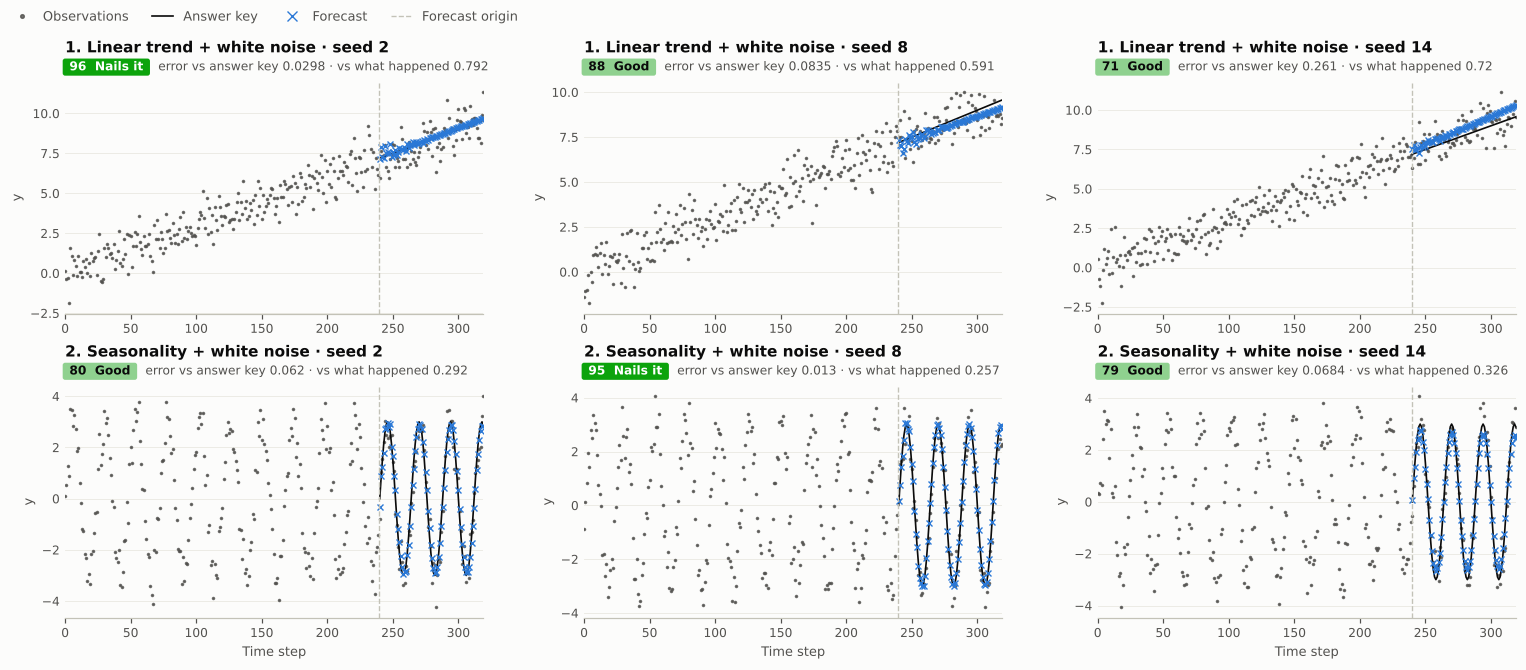

6 cases: 6 passed the output checks, 0 broke them and 0 crashed.


In [15]:
from sklearn.linear_model import Ridge
from sklearn.preprocessing import StandardScaler

pipeline = Pipeline(window_length=24).add(StandardScaler()).add(Ridge(alpha=1.))
specifications = [Scenario('trend', 240, 80, {'slope': .03, 'sigma': .8}),
                  Scenario('seasonal', 240, 80, {'amplitude': 3., 'period': 24., 'sigma': .5})]
run = pipeline.run(specifications, seeds=[2, 8, 14])
assert type(run) is ForecastRun  # built by this chapter's code
run.plot_forecasts(figsize=(14, 6))
plt.show()
counts = run.report.summary['status_counts']
print(f"{len(run.cases)} cases: {counts['PASS']} passed the output checks, "
      f"{counts['FAIL']} broke them and {counts['ERROR']} crashed.")

Each panel is one draw, with its 0-100 score and both errors above it. Ridge follows the cycle in all three draws (scores 80, 95 and 79). On the line it is close in the first draw (96), but its slope is a little off in the other two: too shallow at seed 8 and too steep at seed 14 (71). The plots read the kept forecasts; nothing was fitted again.

### A distribution needs many draws

One draw can be lucky. With 24 draws of each series, `plot_errors` shows how the error against the answer key is spread, again from the kept forecasts:

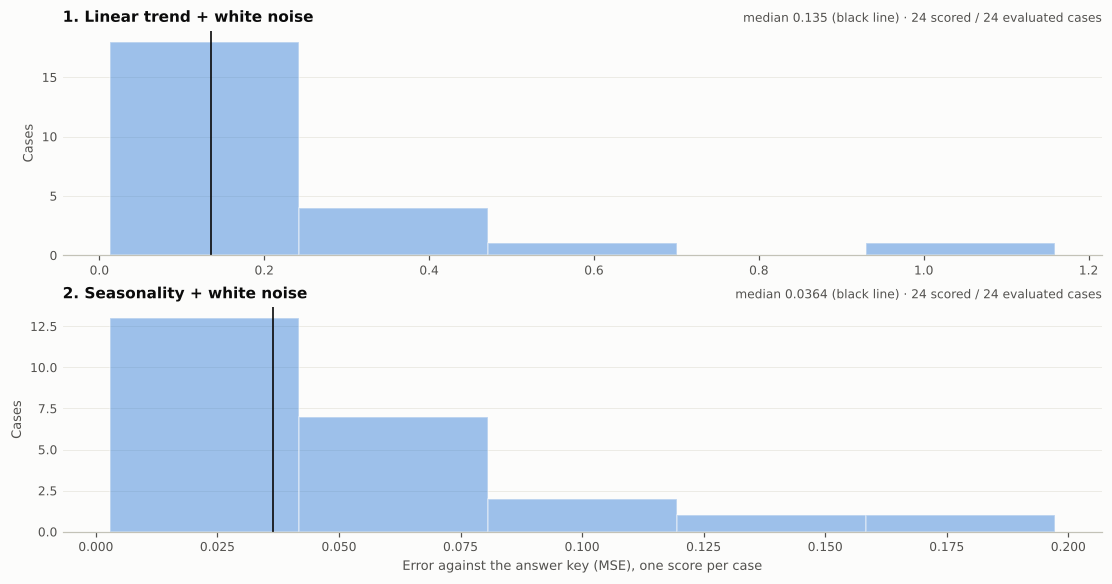

In [16]:
replications = pipeline.run(specifications, seeds=range(24))
replications.plot_errors(metric='mean_reference_mse')
plt.show()

Each draw adds one error to its histogram: the average over its 80 steps. The steps of one forecast move together, so they count as one draw, not 80. On the line the median error is 0.135 and one draw passes 1; on the cycle the median is 0.036 and no draw passes 0.2. A single draw could have landed anywhere in these ranges; the scorecard averages ten draws per cell.

## Change one setting, keep the draws

Draw `i` uses the same seed in every run, so two runs with the same seeds see the same series and can be compared draw by draw. Here the same 24 draws go through the multioutput reduction instead of the recursive one: a single Ridge that predicts all 80 steps at once from the last window, instead of one step at a time fed with its own forecasts.

In [17]:
multioutput = Pipeline(window_length=24, reduction='multioutput').add(StandardScaler()).add(Ridge(alpha=1.))
multioutput_run = multioutput.run(specifications, seeds=range(24))
assert multioutput_run.metadata['reduction'] == 'multioutput'  # the setting is saved with the run
paired = pd.DataFrame({
    'series': [KINDS[entry.case.manifest['kind']] for entry in replications.cases],
    'recursive': [entry.result.metrics['mean_reference_mse'] for entry in replications.cases],
    'multioutput': [entry.result.metrics['mean_reference_mse'] for entry in multioutput_run.cases]})
paired['multioutput is better'] = paired['multioutput'] < paired['recursive']
paired.groupby('series', sort=False).agg(
    **{'recursive, average error': ('recursive', 'mean'),
       'multioutput, average error': ('multioutput', 'mean'),
       'draws where multioutput is better': ('multioutput is better', 'sum')}).round(3)

,"recursive, average error","multioutput, average error",draws where multioutput is better
series,,,
Noise around a straight line,0.206,0.248,9
Noise around a repeating cycle,0.048,0.059,8


On the same 24 draws the recursive reduction is a little better on average, on the line (0.206 against 0.248) and on the cycle (0.048 against 0.059), yet multioutput is better on 9 and 8 of the 24 draws. Pairing the draws shows both the average gap and how often the other choice wins. [Reductions](../tutorials/05_reductions.ipynb) shows when recursive errors compound instead.

`target_transform` changes the scale the model learns on. A price is easier to model as log returns, the change in its logarithm from one step to the next. Here the pipeline fits `ComposedTransform([LogTransform(), DifferenceTransform()])` on each history of a price that jumps now and then, the AR(1) forecasts log returns, and the forecast is turned back into prices before it is scored ([Target engineering](05_target_engineering.ipynb) builds these transforms):

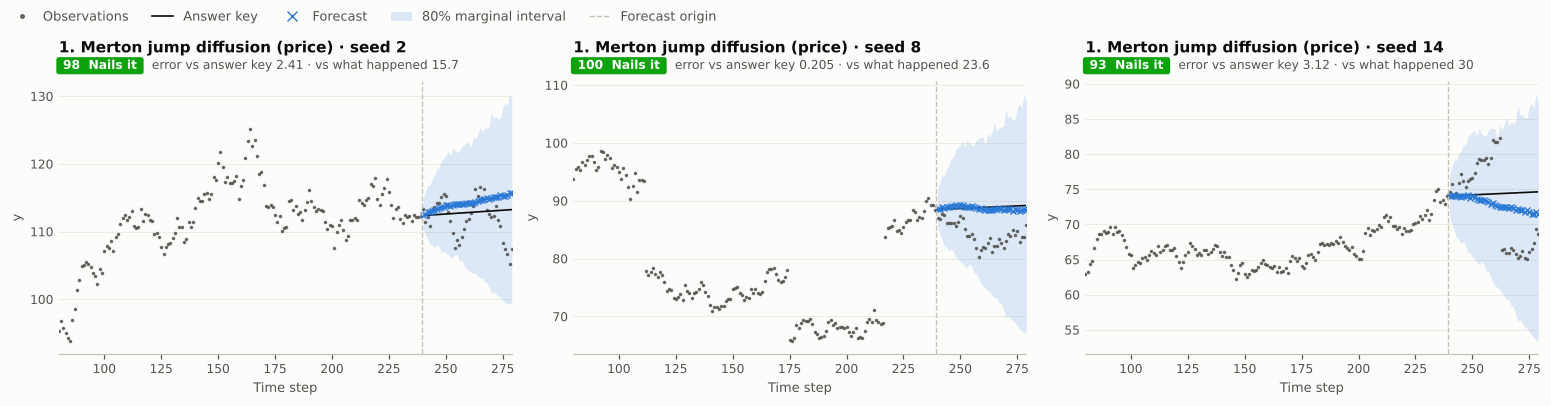

Saved with the run: GaussianAR1Forecaster, target transform LogTransform(), then DifferenceTransform(order=1, lag=1); replayable from the report: True.


In [18]:
from timegym import GaussianAR1Forecaster
from timegym.target import ComposedTransform, DifferenceTransform, LogTransform

prices = Scenario('merton_jump_diffusion', 240, 40, {'output': 'price', 'jump_rate': 2.})
log_returns = Pipeline(GaussianAR1Forecaster(n_samples=200, seed=3),
                       target_transform=ComposedTransform([LogTransform(), DifferenceTransform()]))
price_run = log_returns.run([prices], seeds=[2, 8, 14])
price_run.plot_forecasts(show_quantiles=True, figsize=(14, 3.6))
plt.show()
config = log_returns.to_config()
assert Pipeline.from_config(config).to_config() == config  # the saved settings rebuild the pipeline
steps = config['target_transform']['parameters']['transforms']
print(f"Saved with the run: {config['model']['class']}, target transform "
      + ', then '.join(f"{step['class']}({', '.join(f'{k}={v}' for k, v in step['parameters'].items())})"
                       for step in steps)
      + f"; replayable from the report: {config['replayable']}.")

The AR(1) never saw a price, yet the crosses and the 80% bands are prices, scored against the prices that happened. The bands widen with the horizon, because returns compound. Each case refits the transform on its own history, and the run saves the transform with the model, so a saved report can rebuild both.

**Limits.** A fresh copy keeps cases apart only through the model object: a model that reads files or global state can still carry something from one case to the next. A run holds every series and forecast in memory, while its report keeps only verdicts and scores, so replay regenerates the forecasts rather than reading them. `test` and `run` default to three draws per scenario, with 120 steps of history and 12 to forecast; `plot_tests` uses 240 and 80 so the plots are readable.

## Change one thing

- Make `LastValueForecaster.predict` return one value too few. Which output check fails, and what does `assert_passed()` say?
- Pass the class `RememberingMean` instead of an instance. Is every case still fresh?
- Call `pipeline.run(specifications, seed=None)` and read the base seed it drew from `run.metadata['seed']`.
- Drop `DifferenceTransform()` from the price pipeline, so the AR(1) learns log prices. How do the bands change?

**Next:** [08 · Forecast contracts](08_forecast_contracts.ipynb) defines the history, the dates to forecast and the forecast that every pipeline call passes around. [Write and test a custom model](../tutorials/02_custom_model.ipynb) takes `LastValueForecaster` further.